# Phase 2: Water Quality Classification


## Setup and Configuration


In [4]:
import sys, time, math, importlib, subprocess, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, imblearn, xgboost, scipy

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_FOLDS = 5
QUICK_RUN = False
N_ITER = 4 if QUICK_RUN else 12
N_SEEDS = 3 if QUICK_RUN else 10
N_JOBS = -1

np.random.seed(RANDOM_STATE)


In [5]:
DATA_FILE = 'https://raw.githubusercontent.com/kavinda44/water-quality-baseline/main/waterQuality1.csv'


RESULTS_DIR = Path('results')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset:", DATA_FILE)
print("Results folder:", RESULTS_DIR.resolve())

Dataset: https://raw.githubusercontent.com/kavinda44/water-quality-baseline/main/waterQuality1.csv
Results folder: /content/results


### Published Paper Results


In [6]:
# Transcribed from Karthick et al. (2024), Tables 2, 5–6 and Figures 6, 8.
SAFETY_LIMITS = {
    "aluminium": 2.8, "ammonia": 32.5, "arsenic": 0.01, "barium": 2.0, "cadmium": 0.005,
    "chloramine": 4.0, "chromium": 0.1, "copper": 1.3, "flouride": 1.5, "bacteria": 0.0,
    "viruses": 0.0, "lead": 0.015, "nitrates": 10.0, "nitrites": 1.0, "mercury": 0.002,
    "perchlorate": 56.0, "radium": 5.0, "selenium": 0.5, "silver": 0.1, "uranium": 0.3,
}

PAPER_CONFUSION = {
    ("LightGBM", False): (1392, 8, 52, 148),     ("XGBoost", False): (1389, 11, 48, 152),
    ("CatBoost", False): (1391, 9, 64, 136),     ("Random Forest", False): (1394, 6, 70, 130),
    ("LightGBM", True): (1362, 38, 41, 159),     ("XGBoost", True): (1363, 37, 47, 153),
    ("CatBoost", True): (1368, 32, 53, 147),     ("Random Forest", True): (1347, 53, 51, 149),
}
PAPER_TABLE5 = {
    ("XGBoost", False): (0.9631, 0.933, 0.76, 0.837),   ("LightGBM", False): (0.9625, 0.949, 0.74, 0.831),
    ("CatBoost", False): (0.9544, 0.938, 0.68, 0.788),  ("Random Forest", False): (0.9525, 0.955, 0.65, 0.774),
    ("LightGBM", True): (0.9506, 0.807, 0.795, 0.801),  ("XGBoost", True): (0.9475, 0.805, 0.765, 0.785),
    ("CatBoost", True): (0.9468, 0.821, 0.735, 0.775),  ("Random Forest", True): (0.935, 0.737, 0.745, 0.741),
}
PAPER_LR = {"No SMOTE": {"Accuracy": 0.92, "ROC-AUC": 0.74}, "With SMOTE": {"Accuracy": 0.84, "ROC-AUC": 0.82}}


## 1. Dataset Loading


In [7]:
df = pd.read_csv(DATA_FILE)

print("Dataset Shape:", df.shape)

display(df.head())


Dataset Shape: (7999, 21)


,aluminium,ammonia,arsenic,barium,cadmium,chloramine,chromium,copper,flouride,bacteria,...,lead,nitrates,nitrites,mercury,perchlorate,radium,selenium,silver,uranium,is_safe
0,1.65,9.08,0.04,2.85,0.007,0.35,0.83,0.17,0.05,0.20,...,0.054,16.08,1.13,0.007,37.75,6.78,0.08,0.34,0.02,1
1,2.32,21.16,0.01,3.31,0.002,5.28,0.68,0.66,0.90,0.65,...,0.100,2.01,1.93,0.003,32.26,3.21,0.08,0.27,0.05,1
2,1.01,14.02,0.04,0.58,0.008,4.24,0.53,0.02,0.99,0.05,...,0.078,14.16,1.11,0.006,50.28,7.07,0.07,0.44,0.01,0
3,1.36,11.33,0.04,2.96,0.001,7.23,0.03,1.66,1.08,0.71,...,0.016,1.41,1.29,0.004,9.12,1.72,0.02,0.45,0.05,1
4,0.92,24.33,0.03,0.20,0.006,2.67,0.69,0.57,0.61,0.13,...,0.117,6.74,1.11,0.003,16.90,2.41,0.02,0.06,0.02,1


## 2. Data Cleaning


In [8]:
df_clean = df.copy()

df_clean = df_clean.apply(pd.to_numeric, errors='coerce')

print("Missing Values Before Cleaning:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

df_clean = df_clean.dropna().copy()

df_clean['is_safe'] = df_clean['is_safe'].astype(int)

print("\nOriginal Dataset:", df.shape)
print("Cleaned Dataset:", df_clean.shape)
print("Removed Records:", len(df) - len(df_clean))

print("\nTarget Class Distribution:")
print(df_clean['is_safe'].value_counts().sort_index())


Missing Values Before Cleaning:
ammonia    3
is_safe    3
dtype: int64

Original Dataset: (7999, 21)
Cleaned Dataset: (7996, 21)
Removed Records: 3

Target Class Distribution:
is_safe
0    7084
1     912
Name: count, dtype: int64


In [9]:
neg = (df_clean.drop(columns="is_safe") < 0).sum()
print("Duplicate rows            :", int(df_clean.duplicated().sum()))
print("Negative values by column :", neg[neg > 0].to_dict())
print("Minimum ammonia           :", df_clean["ammonia"].min(), "(a concentration cannot be negative)")


Duplicate rows            : 0
Negative values by column : {'ammonia': 10}
Minimum ammonia           : -0.08 (a concentration cannot be negative)


## 3. Exploratory Data Analysis


Water Quality Class Distribution
-----------------------------------
Not Safe: 7084 samples (88.59%)
Safe: 912 samples (11.41%)


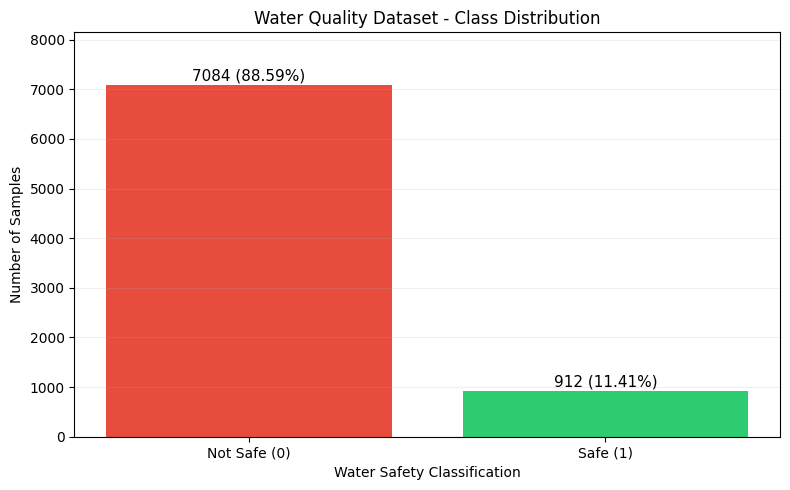

In [10]:
import matplotlib.pyplot as plt

class_counts = df_clean['is_safe'].value_counts().sort_index()

class_percentages = df_clean['is_safe'].value_counts(
    normalize=True
).sort_index() * 100

print("Water Quality Class Distribution")
print("-" * 35)

for class_id, label in [(0, "Not Safe"), (1, "Safe")]:
    print(f"{label}: {class_counts[class_id]} samples "
          f"({class_percentages[class_id]:.2f}%)")

plt.figure(figsize=(8, 5))

labels = ['Not Safe (0)', 'Safe (1)']
colors = ['#E74C3C', '#2ECC71']

bars = plt.bar(labels, class_counts.values, color=colors)

for bar, count, percentage in zip(
    bars, class_counts.values, class_percentages.values
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 100,
        f'{count} ({percentage:.2f}%)',
        ha='center',
        fontsize=11
    )

plt.title('Water Quality Dataset - Class Distribution')
plt.xlabel('Water Safety Classification')
plt.ylabel('Number of Samples')
plt.ylim(0, max(class_counts.values) * 1.15)
plt.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()


### 3.1 Feature Skewness


,skewness
aluminium,2.013
arsenic,1.985
silver,1.029
chromium,1.028
perchlorate,0.938
chloramine,0.888


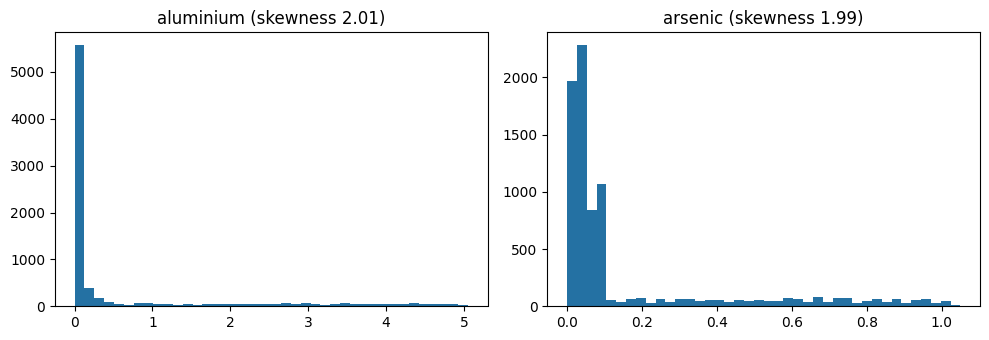

In [11]:
features_all = [c for c in df_clean.columns if c != "is_safe"]
skew = df_clean[features_all].skew().sort_values(ascending=False)
display(skew.round(3).to_frame("skewness").head(6))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col in zip(axes, ["aluminium", "arsenic"]):
    ax.hist(df_clean[col], bins=40, color="#2471a3")
    ax.set_title(f"{col} (skewness {df_clean[col].skew():.2f})")
plt.tight_layout(); plt.show()


### 3.2 Feature Correlations


Largest absolute correlation between two features: 0.619


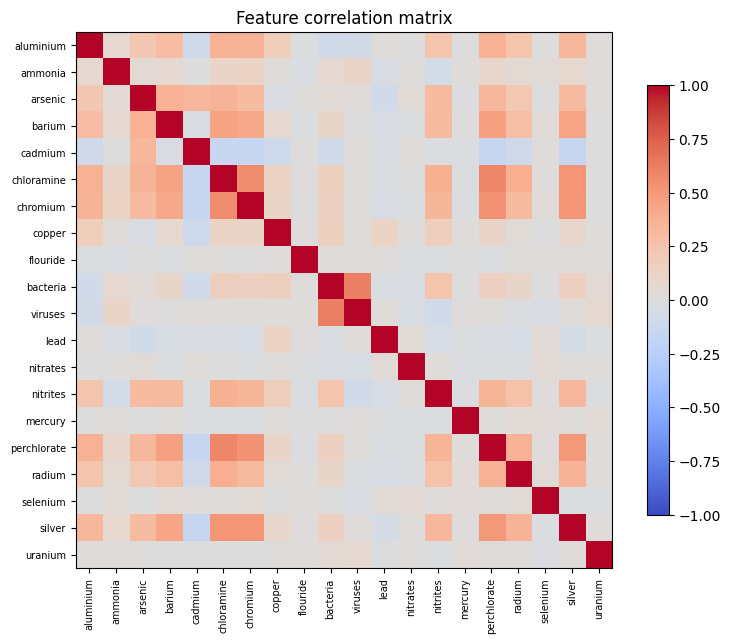

In [12]:
corr = df_clean[features_all].corr()
off_diag = corr.where(~np.eye(len(corr), dtype=bool)).abs()
print("Largest absolute correlation between two features:", round(float(off_diag.max().max()), 3))

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=7)
fig.colorbar(im, shrink=0.8); ax.set_title("Feature correlation matrix")
plt.tight_layout(); plt.show()


### 3.3 Safety Limits and Dataset Labels


In [13]:
exceeded = pd.DataFrame({f: df_clean[f] > lim for f, lim in SAFETY_LIMITS.items()})
n_exceeded = exceeded.sum(axis=1)
safe = df_clean["is_safe"] == 1

print("Samples within ALL limits               :", int((n_exceeded == 0).sum()), "of", len(df_clean))
print("Safe samples exceeding at least 1 limit :", int(((n_exceeded > 0) & safe).sum()), "of", int(safe.sum()))
print("Median limits exceeded (Safe / Not Safe):", float(n_exceeded[safe].median()), "/", float(n_exceeded[~safe].median()))
print("Features that never exceed their limit  :", [f for f in SAFETY_LIMITS if not exceeded[f].any()])


Samples within ALL limits               : 1 of 7996
Safe samples exceeding at least 1 limit : 911 of 912
Median limits exceeded (Safe / Not Safe): 9.0 / 8.0
Features that never exceed their limit  : ['ammonia', 'flouride', 'selenium', 'uranium']


### 3.4 PCA Feature Selection Check


Lowest average |loading|: chloramine 0.099
Uranium rank (1 = lowest): 6 of 20 | value 0.131
Largest value: 0.179 | theoretical maximum: 0.224


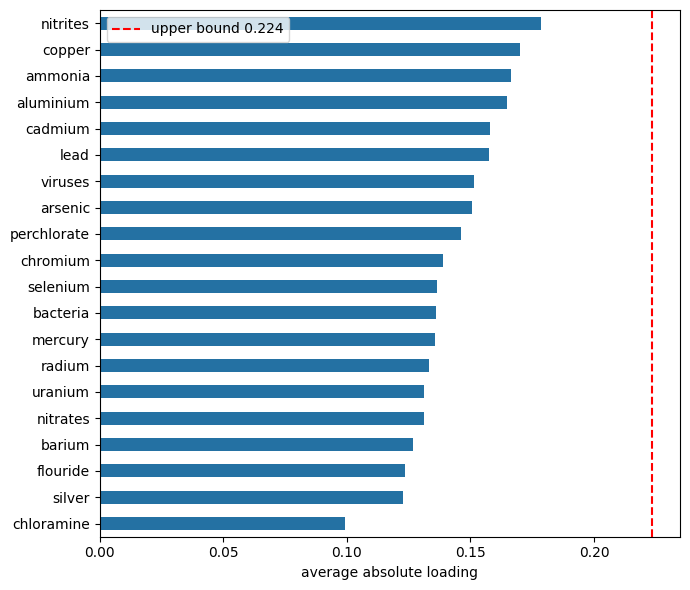

In [14]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import PowerTransformer

Z = PowerTransformer(method="yeo-johnson", standardize=True).fit_transform(df_clean[features_all])
pca = PCA(n_components=None).fit(Z)
mean_abs_loading = pd.Series(np.abs(pca.components_).mean(axis=0), index=features_all).sort_values()
bound = 1 / np.sqrt(len(features_all))

print("Lowest average |loading|:", mean_abs_loading.index[0], round(float(mean_abs_loading.iloc[0]), 3))
print("Uranium rank (1 = lowest):", list(mean_abs_loading.index).index("uranium") + 1, "of", len(features_all),
      "| value", round(float(mean_abs_loading["uranium"]), 3))
print("Largest value:", round(float(mean_abs_loading.max()), 3), "| theoretical maximum:", round(float(bound), 3))

ax = mean_abs_loading.plot.barh(figsize=(7, 6), color="#2471a3")
ax.axvline(bound, color="red", ls="--", label=f"upper bound {bound:.3f}")
ax.set_xlabel("average absolute loading"); ax.legend(); plt.tight_layout(); plt.show()


## 4. Feature Selection and Data Splitting


In [15]:
from sklearn.model_selection import train_test_split

X_all = df_clean.drop(columns=['is_safe'])
y = df_clean['is_safe']

X = X_all.drop(columns=['uranium'])

print("Total Selected Features:", X.shape[1])
print("\nSelected Features:")
print(X.columns.tolist())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

print("\nTraining Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])
print("\nTraining Class Distribution:", y_train.value_counts().sort_index().tolist(), "(Not Safe, Safe)")
print("Testing Class Distribution :", y_test.value_counts().sort_index().tolist(), "(Not Safe, Safe)")

assert y_train.value_counts().sort_index().tolist() == [5684, 712]
assert y_test.value_counts().sort_index().tolist() == [1400, 200]

assert len(X_train) + len(X_test) == len(df_clean)
assert X_train.index.intersection(X_test.index).empty

print("\nTrain/Test Split Completed Successfully")


Total Selected Features: 19

Selected Features:
['aluminium', 'ammonia', 'arsenic', 'barium', 'cadmium', 'chloramine', 'chromium', 'copper', 'flouride', 'bacteria', 'viruses', 'lead', 'nitrates', 'nitrites', 'mercury', 'perchlorate', 'radium', 'selenium', 'silver']

Training Samples: 6396
Testing Samples: 1600

Training Class Distribution: [5684, 712] (Not Safe, Safe)
Testing Class Distribution : [1400, 200] (Not Safe, Safe)

Train/Test Split Completed Successfully


## 5. Transformation and Scaling


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.pipeline import Pipeline

skewed_features = ['aluminium', 'arsenic']

def build_feature_transformer(columns):
    """Yeo-Johnson on the skewed columns that are present; every other column passes through."""
    skewed = [c for c in skewed_features if c in columns]
    others = [c for c in columns if c not in skewed]
    return ColumnTransformer(
        transformers=[
            ('yeo_johnson', PowerTransformer(method='yeo-johnson', standardize=False), skewed),
            ('remaining_features', 'passthrough', others),
        ],
        remainder='drop'
    )

feature_transformer = build_feature_transformer(list(X_train.columns))

preprocessor = Pipeline(steps=[
    ('transform', feature_transformer),
    ('scale', StandardScaler())
])

print("Preprocessing Pipeline Created Successfully!")
print("\nYeo-Johnson Features:", skewed_features)
print("Other Features:", X_train.shape[1] - len(skewed_features))
print("Total Features:", len(X_train.columns))

print("\nPreprocessing Steps:")
for name, step in preprocessor.steps:
    print(f"- {name}: {type(step).__name__}")

print("\nPipeline is ready for model training.")


Preprocessing Pipeline Created Successfully!

Yeo-Johnson Features: ['aluminium', 'arsenic']
Other Features: 17
Total Features: 19

Preprocessing Steps:
- transform: ColumnTransformer
- scale: StandardScaler

Pipeline is ready for model training.


## 6. Evaluation Functions


In [17]:
# Positive class: 1 = Safe; false positives are unsafe samples predicted Safe.
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
                             matthews_corrcoef, precision_recall_curve)

def evaluate_model(name, y_true, y_pred, y_prob):
    """One row of metrics (Safe = positive class)."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Safe Precision': precision_score(y_true, y_pred, zero_division=0),
        'Safe Recall': recall_score(y_true, y_pred, zero_division=0),
        'Safe F1': f1_score(y_true, y_pred, zero_division=0),
        'MCC': matthews_corrcoef(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC (AP)': average_precision_score(y_true, y_prob),
        'False Positives': int(fp),
        'False Negatives': int(fn),
    }

def metrics_from_confusion(tn, fp, fn, tp):
    """Threshold metrics straight from a confusion matrix."""
    n = tn + fp + fn + tp
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    return {'Accuracy': (tp + tn) / n, 'Safe Precision': prec, 'Safe Recall': rec,
            'Safe F1': 2 * prec * rec / (prec + rec) if prec + rec else 0.0,
            'False Positives': fp, 'False Negatives': fn}

def wilson_interval(successes, n, z=1.96):
    """95% Wilson score interval for a proportion."""
    p = successes / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

def fp_at_matched_recall(y_true, y_score, target_recall):
    """False positives when the threshold is moved until Safe-recall reaches target_recall.
    Illustrative: the threshold is chosen on the test scores, so this is not an unbiased estimate."""
    y_true = np.asarray(y_true)
    _, rec, thr = precision_recall_curve(y_true, y_score)
    ok = np.where(rec[:-1] >= target_recall - 1e-12)[0]
    if len(ok) == 0:
        return None
    pred = (y_score >= thr[ok[-1]]).astype(int)
    return int(((pred == 1) & (y_true == 0)).sum())

trained = {}
tuning_log = []
print("Evaluation helpers ready.")


Evaluation helpers ready.


## 7. Reference Baselines


In [18]:
from sklearn.dummy import DummyClassifier

dummy_model = DummyClassifier(strategy='most_frequent')
dummy_model.fit(X_train, y_train)

y_dummy_pred = dummy_model.predict(X_test)
y_dummy_prob = dummy_model.predict_proba(X_test)[:, 1]
dummy_results = evaluate_model('Always Unsafe Baseline', y_test, y_dummy_pred, y_dummy_prob)

limits = pd.Series({k: v for k, v in SAFETY_LIMITS.items() if k in X_test.columns})
n_exc_test = (X_test[limits.index] > limits).sum(axis=1).to_numpy()
rule_results = evaluate_model('Rule: all limits respected', y_test, (n_exc_test == 0).astype(int), -n_exc_test)

sanity_df = pd.DataFrame([dummy_results, rule_results])
display(sanity_df.round(4))


,Model,Accuracy,Safe Precision,Safe Recall,Safe F1,MCC,ROC-AUC,PR-AUC (AP),False Positives,False Negatives
0,Always Unsafe Baseline,0.875,0.0,0.0,0.0,0.0,0.5000,0.1250,0,200
1,Rule: all limits respected,0.875,0.0,0.0,0.0,0.0,0.4532,0.1256,0,200


## 8. Logistic Regression Without SMOTE


In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

logreg_pipeline = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=5000,
        random_state=RANDOM_STATE
    ))
])

param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100]
}

cv = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

grid_search_no_smote = GridSearchCV(
    estimator=logreg_pipeline,
    param_grid=param_grid,
    scoring={'pr_auc': 'average_precision', 'roc_auc': 'roc_auc'},
    cv=cv,
    n_jobs=N_JOBS,
    refit='pr_auc'
)

print("Training Logistic Regression (Without SMOTE)...")

grid_search_no_smote.fit(X_train, y_train)

best_model_no_smote = grid_search_no_smote.best_estimator_
trained['Logistic Regression (No SMOTE)'] = best_model_no_smote

print("\nTraining Completed Successfully!")
print("-" * 45)

print("Best C Parameter:",
      grid_search_no_smote.best_params_['classifier__C'])

print("Best Cross-Validation Average Precision:",
      round(grid_search_no_smote.best_score_, 4))

display(pd.DataFrame(grid_search_no_smote.cv_results_)[
    ['param_classifier__C', 'mean_test_pr_auc', 'std_test_pr_auc', 'rank_test_pr_auc']].round(4))

_i = grid_search_no_smote.best_index_
tuning_log.append({'Model': 'Logistic Regression (No SMOTE)',
                   'cv_pr_auc': grid_search_no_smote.cv_results_['mean_test_pr_auc'][_i],
                   'cv_roc_auc': grid_search_no_smote.cv_results_['mean_test_roc_auc'][_i]})


Training Logistic Regression (Without SMOTE)...

Training Completed Successfully!
---------------------------------------------
Best C Parameter: 1
Best Cross-Validation Average Precision: 0.6788


,param_classifier__C,mean_test_pr_auc,std_test_pr_auc,rank_test_pr_auc
0,0.01,0.6549,0.0317,5
1,0.10,0.6766,0.0299,4
2,1.00,0.6788,0.0295,1
3,10.00,0.6787,0.0295,3
4,100.00,0.6787,0.0295,2


## 9. Logistic Regression With SMOTE


In [20]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import clone

smote_pipeline = ImbPipeline(steps=[

    ('transform', clone(feature_transformer)),

    ('scale', StandardScaler()),

    ('smote', SMOTE(random_state=RANDOM_STATE)),

    ('classifier', LogisticRegression(
        max_iter=5000,
        random_state=RANDOM_STATE
    ))
])

param_grid_smote = {
    'classifier__C': [0.01, 0.1, 1, 10, 100]
}

grid_search_smote = GridSearchCV(
    estimator=smote_pipeline,
    param_grid=param_grid_smote,
    scoring={'pr_auc': 'average_precision', 'roc_auc': 'roc_auc'},
    cv=cv,
    n_jobs=N_JOBS,
    refit='pr_auc',
    error_score='raise'
)

print("Training Logistic Regression (With SMOTE)...")

grid_search_smote.fit(X_train, y_train)

best_model_smote = grid_search_smote.best_estimator_
trained['Logistic Regression (With SMOTE)'] = best_model_smote

print("\nTraining Completed Successfully!")
print("-" * 45)

print("Best C Parameter:",
      grid_search_smote.best_params_['classifier__C'])

print("Best Cross-Validation Average Precision:",
      round(grid_search_smote.best_score_, 4))

_i = grid_search_smote.best_index_
tuning_log.append({'Model': 'Logistic Regression (With SMOTE)',
                   'cv_pr_auc': grid_search_smote.cv_results_['mean_test_pr_auc'][_i],
                   'cv_roc_auc': grid_search_smote.cv_results_['mean_test_roc_auc'][_i]})


Training Logistic Regression (With SMOTE)...

Training Completed Successfully!
---------------------------------------------
Best C Parameter: 0.01
Best Cross-Validation Average Precision: 0.5876


## 10. Model Tuning and Class Weights


In [21]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from scipy.stats import loguniform, uniform

SCORING = {'pr_auc': 'average_precision', 'roc_auc': 'roc_auc'}

def build_pipeline(estimator, strategy, columns=None, seed=RANDOM_STATE):
    """Leak-free pipeline. strategy: 'none', 'smote' or 'class_weight' (the weights are set on the estimator)."""
    columns = list(X_train.columns) if columns is None else list(columns)
    steps = [('transform', build_feature_transformer(columns)), ('scale', StandardScaler())]
    if strategy == 'smote':
        steps.append(('smote', SMOTE(random_state=seed)))
    steps.append(('classifier', estimator))
    return ImbPipeline(steps)

def with_class_weight(estimator, y_tr):
    est = clone(estimator)
    if isinstance(est, XGBClassifier):
        est.set_params(scale_pos_weight=float((y_tr == 0).sum() / (y_tr == 1).sum()))
    else:
        est.set_params(class_weight='balanced')
    return est

def tune_model(label, estimator, param_dist, strategy, n_iter=N_ITER):
    """Random search with 5-fold stratified CV; returns the refitted best pipeline and a log row."""
    t0 = time.time()
    search = RandomizedSearchCV(
        build_pipeline(estimator, strategy),
        {f'classifier__{k}': v for k, v in param_dist.items()},
        n_iter=n_iter, scoring=SCORING, refit='pr_auc', cv=cv,
        n_jobs=N_JOBS, random_state=RANDOM_STATE)
    search.fit(X_train, y_train)
    i = search.best_index_
    info = {'Model': label, 'cv_pr_auc': search.cv_results_['mean_test_pr_auc'][i],
            'cv_roc_auc': search.cv_results_['mean_test_roc_auc'][i],
            'seconds': time.time() - t0,
            'best_params': {k.replace('classifier__', ''): v for k, v in search.best_params_.items()}}
    tuning_log.append(info)
    trained[label] = search.best_estimator_
    print(f"{label:38s} CV PR-AUC {info['cv_pr_auc']:.3f} | CV ROC-AUC {info['cv_roc_auc']:.3f} | {info['seconds']:.0f}s")
    return search.best_estimator_

lr_space = {'C': [0.01, 0.1, 1, 10, 100]}
lr_base = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)
tune_model('Logistic Regression (Class Weights)', with_class_weight(lr_base, y_train),
           lr_space, 'class_weight', n_iter=5)


Logistic Regression (Class Weights)    CV PR-AUC 0.586 | CV ROC-AUC 0.891 | 1s


Pipeline(steps=[('transform',
                 ColumnTransformer(transformers=[('yeo_johnson',
                                                  PowerTransformer(standardize=False),
                                                  ['aluminium', 'arsenic']),
                                                 ('remaining_features',
                                                  'passthrough',
                                                  ['ammonia', 'barium',
                                                   'cadmium', 'chloramine',
                                                   'chromium', 'copper',
                                                   'flouride', 'bacteria',
                                                   'viruses', 'lead',
                                                   'nitrates', 'nitrites',
                                                   'mercury', 'perchlorate',
                                                   'radium', 'selenium',
                                                   'silver'])])),
                ('scale', StandardScaler()),
                ('classifier',
                 LogisticRegression(C=0.1, class_weight='balanced',
                                    max_iter=5000, random_state=42))])

## 11. Random Forest


In [22]:
rf_space = {
    'n_estimators': [100, 200],
    'max_depth': [None, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8],
    'max_features': ['sqrt', 'log2', 0.5],
}
rf_base = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)

for strategy, label in [('none', 'Random Forest (No SMOTE)'),
                        ('smote', 'Random Forest (With SMOTE)'),
                        ('class_weight', 'Random Forest (Class Weights)')]:
    est = with_class_weight(rf_base, y_train) if strategy == 'class_weight' else clone(rf_base)
    tune_model(label, est, rf_space, strategy)


Random Forest (No SMOTE)               CV PR-AUC 0.876 | CV ROC-AUC 0.974 | 118s
Random Forest (With SMOTE)             CV PR-AUC 0.853 | CV ROC-AUC 0.977 | 298s
Random Forest (Class Weights)          CV PR-AUC 0.879 | CV ROC-AUC 0.979 | 95s


## 12. XGBoost


In [23]:
xgb_space = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': loguniform(0.02, 0.3),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
}
xgb_base = XGBClassifier(random_state=RANDOM_STATE, n_jobs=1, tree_method='hist', eval_metric='logloss')

for strategy, label in [('none', 'XGBoost (No SMOTE)'),
                        ('smote', 'XGBoost (With SMOTE)'),
                        ('class_weight', 'XGBoost (Class Weights)')]:
    est = with_class_weight(xgb_base, y_train) if strategy == 'class_weight' else clone(xgb_base)
    tune_model(label, est, xgb_space, strategy)


XGBoost (No SMOTE)                     CV PR-AUC 0.897 | CV ROC-AUC 0.980 | 22s
XGBoost (With SMOTE)                   CV PR-AUC 0.874 | CV ROC-AUC 0.975 | 37s
XGBoost (Class Weights)                CV PR-AUC 0.898 | CV ROC-AUC 0.981 | 25s


## 13. Model Evaluation


In [24]:
scores = {}
rows = [dummy_results, rule_results]
for name, model in trained.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    scores[name] = (y_pred, y_prob)
    rows.append(evaluate_model(name, y_test, y_pred, y_prob))

results_df = pd.DataFrame(rows)

ci = [wilson_interval(round(a * len(y_test)), len(y_test)) for a in results_df['Accuracy']]
results_df['Accuracy 95% CI'] = [f"{lo:.3f}-{hi:.3f}" for lo, hi in ci]

results_df.to_csv(RESULTS_DIR / 'model_evaluation_results.csv', index=False)

print("MODEL PERFORMANCE COMPARISON (authors' test split, 1,600 rows)")
print("False Positives = unsafe water predicted Safe (the dangerous error)")
print("-" * 70)
display(results_df.round(4))


MODEL PERFORMANCE COMPARISON (authors' test split, 1,600 rows)
False Positives = unsafe water predicted Safe (the dangerous error)
----------------------------------------------------------------------


,Model,Accuracy,Safe Precision,Safe Recall,Safe F1,MCC,ROC-AUC,PR-AUC (AP),False Positives,False Negatives,Accuracy 95% CI
0,Always Unsafe Baseline,0.8750,0.0000,0.000,0.0000,0.0000,0.5000,0.1250,0,200,0.858-0.890
1,Rule: all limits respected,0.8750,0.0000,0.000,0.0000,0.0000,0.4532,0.1256,0,200,0.858-0.890
2,Logistic Regression (No SMOTE),0.9225,0.8065,0.500,0.6173,0.5972,0.8746,0.7077,24,100,0.908-0.935
3,Logistic Regression (With SMOTE),0.8369,0.4182,0.780,0.5445,0.4889,0.8870,0.6217,217,44,0.818-0.854
4,Logistic Regression (Class Weights),0.8381,0.4209,0.785,0.5480,0.4933,0.8875,0.6251,216,43,0.819-0.855
5,Random Forest (No SMOTE),0.9519,0.9556,0.645,0.7701,0.7624,0.9850,0.9231,6,71,0.940-0.961
6,Random Forest (With SMOTE),0.9462,0.7336,0.895,0.8063,0.7806,0.9837,0.8971,65,21,0.934-0.956
7,Random Forest (Class Weights),0.9556,0.7919,0.875,0.8314,0.8072,0.9877,0.9305,46,25,0.944-0.965
8,XGBoost (No SMOTE),0.9588,0.9527,0.705,0.8103,0.7990,0.9886,0.9390,7,59,0.948-0.967
9,XGBoost (With SMOTE),0.9588,0.8722,0.785,0.8263,0.8044,0.9867,0.9249,23,43,0.948-0.967


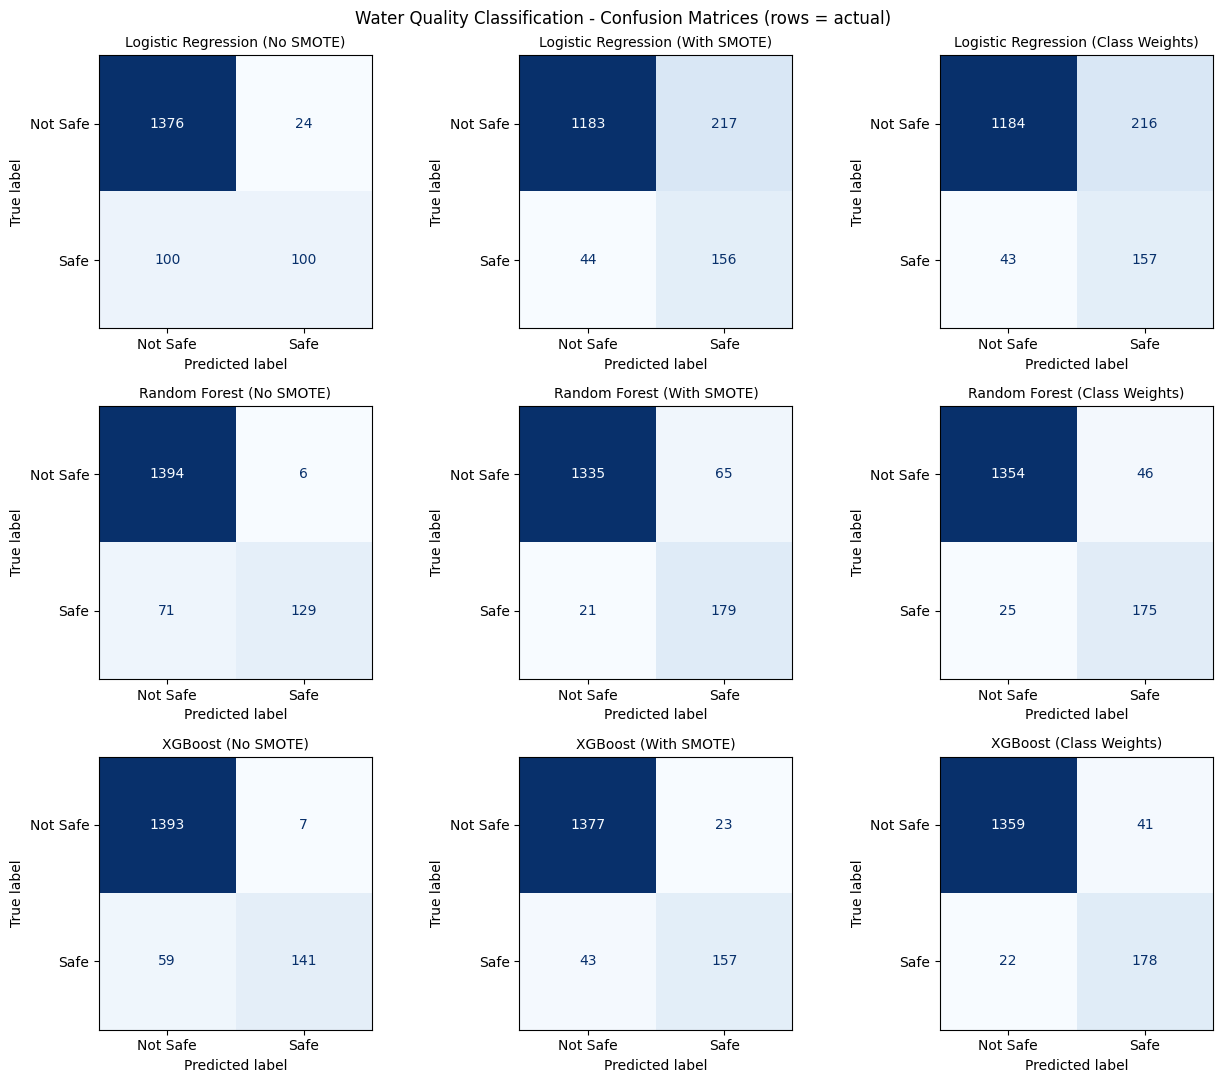

In [25]:
names = list(trained)
fig, axes = plt.subplots(3, 3, figsize=(13, 11))
for ax, name in zip(axes.ravel(), names):
    cm = confusion_matrix(y_test, scores[name][0], labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=['Not Safe', 'Safe']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name, fontsize=10)
plt.suptitle('Water Quality Classification - Confusion Matrices (rows = actual)')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'confusion_matrices.png', dpi=200, bbox_inches='tight')
plt.show()


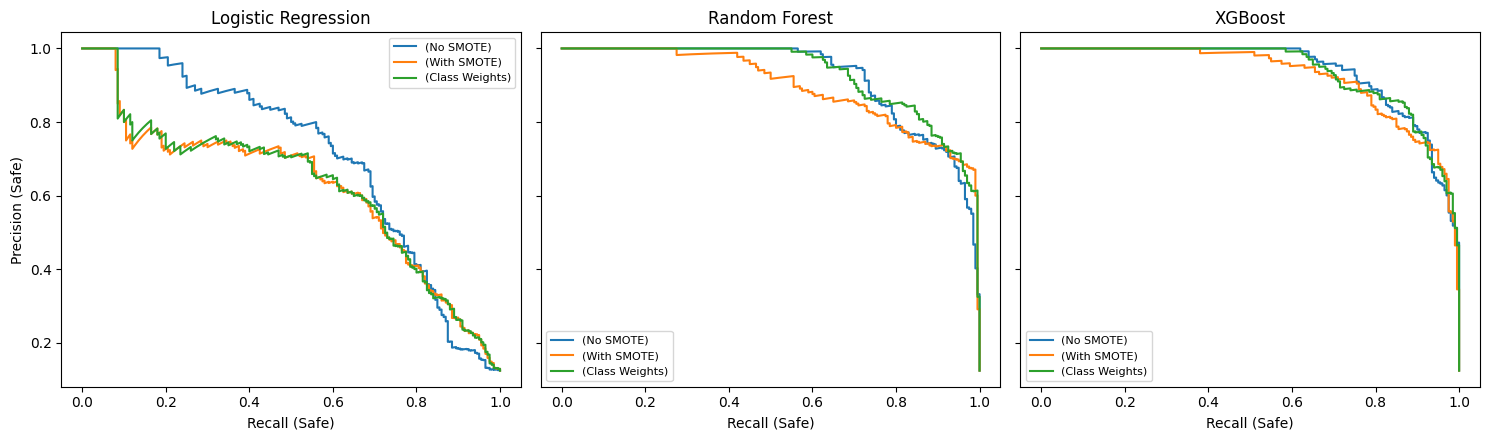

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, fam in zip(axes, ['Logistic Regression', 'Random Forest', 'XGBoost']):
    for name in [n for n in trained if n.startswith(fam)]:
        p, r, _ = precision_recall_curve(y_test, scores[name][1])
        ax.plot(r, p, label=name.replace(fam + ' ', ''))
    ax.set_title(fam); ax.set_xlabel('Recall (Safe)'); ax.legend(fontsize=8)
axes[0].set_ylabel('Precision (Safe)')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'pr_curves.png', dpi=200, bbox_inches='tight')
plt.show()


## 14. Comparison with Karthick et al. (2024)


,Source,Model,Handling,Accuracy,Accuracy 95% CI,Safe Precision,Safe Recall,Safe F1,False Positives,False Negatives
0,Paper,LightGBM,none,0.9625,0.952-0.971,0.9487,0.740,0.8315,8,52
1,Paper,XGBoost,none,0.9631,0.953-0.971,0.9325,0.760,0.8375,11,48
2,Paper,CatBoost,none,0.9544,0.943-0.964,0.9379,0.680,0.7884,9,64
3,Paper,Random Forest,none,0.9525,0.941-0.962,0.9559,0.650,0.7738,6,70
4,Paper,LightGBM,SMOTE,0.9506,0.939-0.960,0.8071,0.795,0.8010,38,41
5,Paper,XGBoost,SMOTE,0.9475,0.935-0.957,0.8053,0.765,0.7846,37,47
6,Paper,CatBoost,SMOTE,0.9469,0.935-0.957,0.8212,0.735,0.7757,32,53
7,Paper,Random Forest,SMOTE,0.9350,0.922-0.946,0.7376,0.745,0.7413,53,51
8,Ours,Logistic Regression,none,0.9225,0.908-0.935,0.8065,0.500,0.6173,24,100
9,Ours,Logistic Regression,SMOTE,0.8369,0.818-0.854,0.4182,0.780,0.5445,217,44


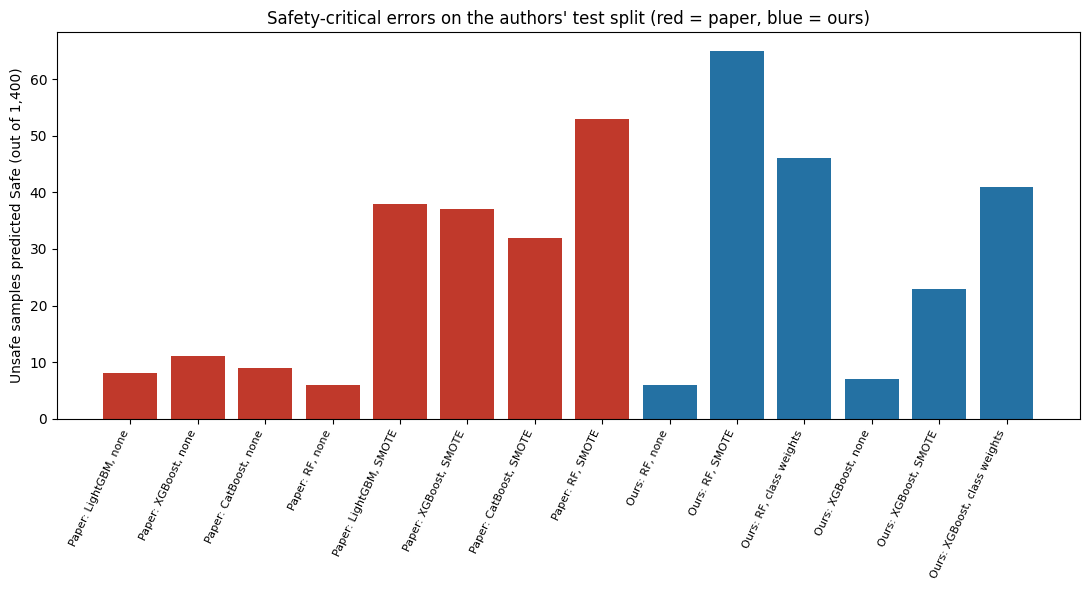

In [27]:
paper_rows = []
for (model, smote), cm in PAPER_CONFUSION.items():
    lo, hi = wilson_interval(cm[0] + cm[3], sum(cm))
    paper_rows.append({'Source': 'Paper', 'Model': model, 'Handling': 'SMOTE' if smote else 'none',
                       **metrics_from_confusion(*cm), 'Accuracy 95% CI': f"{lo:.3f}-{hi:.3f}"})

def handling(name):
    return 'SMOTE' if 'With SMOTE' in name else 'class weights' if 'Class Weights' in name else 'none'

ours_rows = []
for _, r in results_df[results_df['Model'].isin(trained)].iterrows():
    ours_rows.append({'Source': 'Ours', 'Model': r['Model'].split(' (')[0], 'Handling': handling(r['Model']),
                      'Accuracy': r['Accuracy'], 'Safe Precision': r['Safe Precision'], 'Safe Recall': r['Safe Recall'],
                      'Safe F1': r['Safe F1'], 'False Positives': r['False Positives'],
                      'False Negatives': r['False Negatives'], 'Accuracy 95% CI': r['Accuracy 95% CI']})

paper_vs_ours = pd.concat([pd.DataFrame(paper_rows), pd.DataFrame(ours_rows)], ignore_index=True)
cols = ['Source', 'Model', 'Handling', 'Accuracy', 'Accuracy 95% CI', 'Safe Precision', 'Safe Recall',
        'Safe F1', 'False Positives', 'False Negatives']
paper_vs_ours = paper_vs_ours[cols]
paper_vs_ours.to_csv(RESULTS_DIR / 'paper_vs_ours.csv', index=False)
display(paper_vs_ours.round(4))

d = paper_vs_ours[paper_vs_ours['Model'] != 'Logistic Regression'].reset_index(drop=True)
labels = d['Source'] + ': ' + d['Model'].str.replace('Random Forest', 'RF') + ', ' + d['Handling']
plt.figure(figsize=(11, 6))
plt.bar(range(len(d)), d['False Positives'], color=d['Source'].map({'Paper': '#c0392b', 'Ours': '#2471a3'}))
plt.xticks(range(len(d)), labels, rotation=65, ha='right', fontsize=8)
plt.ylabel('Unsafe samples predicted Safe (out of 1,400)')
plt.title("Safety-critical errors on the authors' test split (red = paper, blue = ours)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'false_positives_paper_vs_ours.png', dpi=200, bbox_inches='tight')
plt.show()


,Setting,Paper Accuracy (%),Our Accuracy (%),Accuracy Difference (pp),Paper ROC-AUC,Our ROC-AUC
0,No SMOTE,92.0,92.2500,0.2500,0.74,0.8746
1,With SMOTE,84.0,83.6875,-0.3125,0.82,0.8870


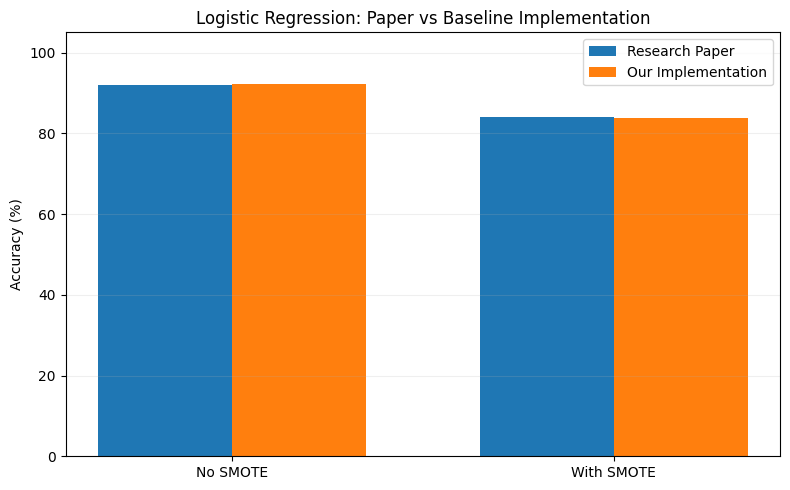

In [28]:
our_lr = results_df.set_index('Model')
lr_names = {'No SMOTE': 'Logistic Regression (No SMOTE)', 'With SMOTE': 'Logistic Regression (With SMOTE)'}
comparison = []
for setting, model_name in lr_names.items():
    paper, ours = PAPER_LR[setting], our_lr.loc[model_name]
    comparison.append({
        'Setting': setting,
        'Paper Accuracy (%)': paper['Accuracy'] * 100,
        'Our Accuracy (%)': ours['Accuracy'] * 100,
        'Accuracy Difference (pp)': (ours['Accuracy'] - paper['Accuracy']) * 100,
        'Paper ROC-AUC': paper['ROC-AUC'],
        'Our ROC-AUC': ours['ROC-AUC'],
    })
paper_comparison_df = pd.DataFrame(comparison)
display(paper_comparison_df.round(4))
paper_comparison_df.to_csv(RESULTS_DIR / 'paper_comparison_lr.csv', index=False)

x = np.arange(len(paper_comparison_df)); width = 0.35
plt.figure(figsize=(8, 5))
plt.bar(x - width / 2, paper_comparison_df['Paper Accuracy (%)'], width, label='Research Paper')
plt.bar(x + width / 2, paper_comparison_df['Our Accuracy (%)'], width, label='Our Implementation')
plt.xticks(x, paper_comparison_df['Setting']); plt.ylabel('Accuracy (%)'); plt.ylim(0, 105)
plt.title('Logistic Regression: Paper vs Baseline Implementation'); plt.legend()
plt.grid(axis='y', alpha=0.2); plt.tight_layout()
plt.savefig(RESULTS_DIR / 'paper_accuracy_comparison.png', dpi=200, bbox_inches='tight')
plt.show()


## 15. Additional Experiments


### 15.1 SMOTE and Decision Thresholds


In [29]:
# Matched-recall thresholds are chosen on the test set; use for illustration only.
op_rows = []
for fam in ['Logistic Regression', 'Random Forest', 'XGBoost']:
    none = results_df.set_index('Model').loc[f'{fam} (No SMOTE)']
    for tag in ['With SMOTE', 'Class Weights']:
        other = results_df.set_index('Model').loc[f'{fam} ({tag})']
        op_rows.append({
            'Model': fam, 'Strategy': tag,
            'Safe recall (strategy)': other['Safe Recall'], 'FP (strategy)': other['False Positives'],
            'FP (no handling, default threshold)': none['False Positives'],
            'FP (no handling, threshold moved to same recall)':
                fp_at_matched_recall(y_test, scores[f'{fam} (No SMOTE)'][1], other['Safe Recall']),
        })
operating_point_df = pd.DataFrame(op_rows)
operating_point_df.to_csv(RESULTS_DIR / 'operating_point.csv', index=False)
display(operating_point_df.round(3))


,Model,Strategy,Safe recall (strategy),FP (strategy),"FP (no handling, default threshold)","FP (no handling, threshold moved to same recall)"
0,Logistic Regression,With SMOTE,0.780,217,24,180
1,Logistic Regression,Class Weights,0.785,216,24,194
2,Random Forest,With SMOTE,0.895,65,6,63
3,Random Forest,Class Weights,0.875,46,6,57
4,XGBoost,With SMOTE,0.785,23,7,16
5,XGBoost,Class Weights,0.890,41,7,41


### 15.2 Preprocessing Leakage Sensitivity


In [30]:
def run_paper_style(label, base_estimator, param_dist, strategy, n_iter=N_ITER):
    """Protocol A: global transform -> split -> SMOTE once -> randomised search (the authors' order)."""
    pre = Pipeline([('transform', build_feature_transformer(list(X.columns))), ('scale', StandardScaler())])
    Xt = pre.fit_transform(X)
    Xtr, Xte, ytr, yte = train_test_split(Xt, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)
    assert (np.asarray(yte) == np.asarray(y_test)).all()
    if strategy == 'smote':
        Xtr, ytr = SMOTE(random_state=RANDOM_STATE).fit_resample(Xtr, ytr)
    search = RandomizedSearchCV(clone(base_estimator), param_dist, n_iter=n_iter, scoring=SCORING,
                                refit='pr_auc', cv=cv, n_jobs=N_JOBS, random_state=RANDOM_STATE).fit(Xtr, ytr)
    i = search.best_index_
    pred, prob = search.predict(Xte), search.predict_proba(Xte)[:, 1]
    m = evaluate_model(label, yte, pred, prob)
    m['cv_roc_auc'] = search.cv_results_['mean_test_roc_auc'][i]
    return m

plan = [('Logistic Regression', lr_base, lr_space, 5), ('Random Forest', rf_base, rf_space, N_ITER),
        ('XGBoost', xgb_base, xgb_space, N_ITER)]
leak_rows = []
for fam, base, space, n_it in plan:
    for strategy, tag in [('none', 'No SMOTE'), ('smote', 'With SMOTE')]:
        a = run_paper_style(f'{fam} ({tag})', base, space, strategy, n_iter=n_it)
        b = results_df.set_index('Model').loc[f'{fam} ({tag})']
        b_cv = next(t['cv_roc_auc'] for t in tuning_log if t['Model'] == f'{fam} ({tag})') \
            if any(t['Model'] == f'{fam} ({tag})' for t in tuning_log) else float('nan')
        leak_rows.append({
            'Model': f'{fam} ({tag})',
            'Accuracy (paper order)': a['Accuracy'], 'Accuracy (leak-free)': b['Accuracy'],
            'FP (paper order)': a['False Positives'], 'FP (leak-free)': b['False Positives'],
            'CV minus test ROC-AUC (paper order)': a['cv_roc_auc'] - a['ROC-AUC'],
            'CV minus test ROC-AUC (leak-free)': b_cv - b['ROC-AUC'],
        })
        print('done:', fam, tag)
leakage_df = pd.DataFrame(leak_rows)
leakage_df.to_csv(RESULTS_DIR / 'leakage_experiment.csv', index=False)
display(leakage_df.round(4))


done: Logistic Regression No SMOTE
done: Logistic Regression With SMOTE
done: Random Forest No SMOTE
done: Random Forest With SMOTE
done: XGBoost No SMOTE
done: XGBoost With SMOTE


,Model,Accuracy (paper order),Accuracy (leak-free),FP (paper order),FP (leak-free),CV minus test ROC-AUC (paper order),CV minus test ROC-AUC (leak-free)
0,Logistic Regression (No SMOTE),0.9225,0.9225,24,24,0.0036,0.0036
1,Logistic Regression (With SMOTE),0.8362,0.8369,218,217,0.0157,0.0020
2,Random Forest (No SMOTE),0.9519,0.9519,6,6,-0.0105,-0.0106
3,Random Forest (With SMOTE),0.9456,0.9462,47,65,0.0170,-0.0071
4,XGBoost (No SMOTE),0.9588,0.9588,7,7,-0.0083,-0.0083
5,XGBoost (With SMOTE),0.9600,0.9588,25,23,0.0128,-0.0116


### 15.3 Results Across Different Data Splits


In [31]:
seed_rows = []
for seed in range(N_SEEDS):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=TEST_SIZE, random_state=seed, stratify=y)
    for fam, base in [('Logistic Regression', LogisticRegression(max_iter=5000)),
                      ('Random Forest', RandomForestClassifier(n_estimators=200, n_jobs=-1))]:
        for strategy, tag in [('none', 'No SMOTE'), ('smote', 'With SMOTE'), ('class_weight', 'Class Weights')]:
            est = with_class_weight(base, ytr) if strategy == 'class_weight' else clone(base)
            est.set_params(random_state=seed)
            pipe = build_pipeline(est, strategy, seed=seed).fit(Xtr, ytr)
            m = evaluate_model(f'{fam} ({tag})', yte, pipe.predict(Xte), pipe.predict_proba(Xte)[:, 1])
            seed_rows.append({'seed': seed, **m})

seed_df = pd.DataFrame(seed_rows)
seed_summary = seed_df.groupby('Model')[['Accuracy', 'Safe Precision', 'Safe Recall', 'MCC', 'ROC-AUC', 'False Positives']] \
    .agg(['mean', 'std']).round(4)
seed_df.to_csv(RESULTS_DIR / 'seed_study_raw.csv', index=False)
seed_summary.to_csv(RESULTS_DIR / 'seed_study_summary.csv')
display(seed_summary)


Accuracy         Safe Precision          \
                                        mean     std           mean     std   
Model                                                                         
Logistic Regression (Class Weights)   0.8284  0.0050         0.3775  0.0087   
Logistic Regression (No SMOTE)        0.9278  0.0040         0.7636  0.0187   
Logistic Regression (With SMOTE)      0.8307  0.0049         0.3809  0.0088   
Random Forest (Class Weights)         0.9502  0.0029         0.9075  0.0190   
Random Forest (No SMOTE)              0.9515  0.0040         0.9207  0.0216   
Random Forest (With SMOTE)            0.9470  0.0054         0.7678  0.0363   

                                    Safe Recall             MCC          \
                                           mean     std    mean     std   
Model                                                                     
Logistic Regression (Class Weights)      0.7830  0.0330  0.4616  0.0177   
Logistic Regression (No SMOTE)           0.5280  0.0292  0.5980  0.0259   
Logistic Regression (With SMOTE)         0.7797  0.0349  0.4635  0.0185   
Random Forest (Class Weights)            0.6264  0.0288  0.7295  0.0179   
Random Forest (No SMOTE)                 0.6280  0.0329  0.7369  0.0235   
Random Forest (With SMOTE)               0.7687  0.0262  0.7381  0.0239   

                                    ROC-AUC         False Positives           
                                       mean     std            mean      std  
Model                                                                         
Logistic Regression (Class Weights)  0.8891  0.0133           235.0  10.3816  
Logistic Regression (No SMOTE)       0.8789  0.0188            29.7   2.1628  
Logistic Regression (With SMOTE)     0.8883  0.0135           230.7  10.3821  
Random Forest (Class Weights)        0.9801  0.0042            11.7   3.0203  
Random Forest (No SMOTE)             0.9746  0.0049             9.9   2.9981  
Random Forest (With SMOTE)           0.9754  0.0042            42.7   8.8951

### 15.4 Feature Ablation: Uranium


In [32]:
Xtr_all, Xte_all, ytr_all, yte_all = train_test_split(X_all, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)
assert (np.asarray(yte_all) == np.asarray(y_test)).all()

abl_rows = []
for fam in ['Logistic Regression', 'Random Forest', 'XGBoost']:
    best_est = trained[f'{fam} (No SMOTE)'].named_steps['classifier']
    for variant, cols in [('All 20 features', list(X_all.columns)), ('Uranium removed (paper)', list(X.columns))]:
        pipe = build_pipeline(clone(best_est), 'none', columns=cols)
        pipe.fit(Xtr_all[cols], ytr_all)
        m = evaluate_model(fam, yte_all, pipe.predict(Xte_all[cols]), pipe.predict_proba(Xte_all[cols])[:, 1])
        abl_rows.append({'Model': fam, 'Features': variant, 'Accuracy': m['Accuracy'], 'Safe Recall': m['Safe Recall'],
                         'ROC-AUC': m['ROC-AUC'], 'False Positives': m['False Positives']})
ablation_df = pd.DataFrame(abl_rows)
ablation_df.to_csv(RESULTS_DIR / 'feature_ablation.csv', index=False)
display(ablation_df.round(4))


,Model,Features,Accuracy,Safe Recall,ROC-AUC,False Positives
0,Logistic Regression,All 20 features,0.9188,0.485,0.8817,27
1,Logistic Regression,Uranium removed (paper),0.9225,0.500,0.8746,24
2,Random Forest,All 20 features,0.9694,0.780,0.9885,5
3,Random Forest,Uranium removed (paper),0.9519,0.645,0.9850,6
4,XGBoost,All 20 features,0.9706,0.800,0.9933,7
5,XGBoost,Uranium removed (paper),0.9588,0.705,0.9886,7


## 16. Automated Tests


In [33]:
import unittest
from sklearn.base import BaseEstimator, ClassifierMixin

class SpyClassifier(BaseEstimator, ClassifierMixin):
    """Records what the classifier receives at fit time (used to test SMOTE placement)."""
    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.fit_counts_ = np.bincount(np.asarray(y))
        return self
    def predict(self, X):
        return np.zeros(len(X), dtype=int)
    def predict_proba(self, X):
        return np.tile([1.0, 0.0], (len(X), 1))

class TestWaterQualityPipeline(unittest.TestCase):

    def test_01_cleaning_removes_all_missing_values(self):
        self.assertEqual(df_clean.shape, (7996, 21))
        self.assertEqual(int(df_clean.isna().sum().sum()), 0)

    def test_02_class_counts_match_paper(self):
        self.assertEqual(df_clean['is_safe'].value_counts().sort_index().tolist(), [7084, 912])

    def test_03_split_reproduces_authors_counts(self):
        self.assertEqual(y_train.value_counts().sort_index().tolist(), [5684, 712])
        self.assertEqual(y_test.value_counts().sort_index().tolist(), [1400, 200])

    def test_04_no_row_overlap_between_train_and_test(self):
        self.assertTrue(X_train.index.intersection(X_test.index).empty)

    def test_05_uranium_removed_leaves_19_features(self):
        self.assertNotIn('uranium', X_train.columns)
        self.assertEqual(X_train.shape[1], 19)

    def test_06_yeo_johnson_learned_from_training_rows_only(self):
        pipe = build_pipeline(SpyClassifier(), 'none').fit(X_train, y_train)
        lam = pipe.named_steps['transform'].named_transformers_['yeo_johnson'].lambdas_
        train_only = PowerTransformer(standardize=False).fit(X_train[skewed_features]).lambdas_
        everything = PowerTransformer(standardize=False).fit(X[skewed_features]).lambdas_
        np.testing.assert_allclose(lam, train_only)
        self.assertFalse(np.allclose(lam, everything))

    def test_07_smote_balances_training_data_only(self):
        spy = SpyClassifier()
        pipe = build_pipeline(spy, 'smote').fit(X_train, y_train)
        self.assertEqual(spy.fit_counts_[0], spy.fit_counts_[1])
        self.assertEqual(len(pipe.predict(X_test)), len(X_test))

    def test_08_without_smote_class_counts_are_untouched(self):
        spy = SpyClassifier()
        build_pipeline(spy, 'none').fit(X_train, y_train)
        np.testing.assert_array_equal(spy.fit_counts_, np.bincount(y_train))

    def test_09_same_seed_gives_identical_probabilities(self):
        def run():
            rf = RandomForestClassifier(n_estimators=30, random_state=7)
            return build_pipeline(rf, 'smote', seed=7).fit(X_train, y_train).predict_proba(X_test)
        np.testing.assert_array_equal(run(), run())

    def test_10_metrics_match_known_confusion_matrix(self):
        m = metrics_from_confusion(1392, 8, 52, 148)
        self.assertAlmostEqual(m['Accuracy'], 0.9625)
        self.assertAlmostEqual(m['Safe Recall'], 0.74)
        self.assertEqual(m['False Positives'], 8)

    def test_11_paper_confusion_matrices_reproduce_table5(self):
        for key, cm in PAPER_CONFUSION.items():
            m = metrics_from_confusion(*cm)
            acc, prec, rec, f1 = PAPER_TABLE5[key]
            self.assertAlmostEqual(m['Accuracy'], acc, delta=1e-3)
            self.assertAlmostEqual(m['Safe Precision'], prec, delta=2e-3)
            self.assertAlmostEqual(m['Safe Recall'], rec, delta=1e-3)
            self.assertAlmostEqual(m['Safe F1'], f1, delta=2e-3)

    def test_12_probabilities_valid_and_dummy_equals_majority_share(self):
        for name, (_, prob) in scores.items():
            self.assertTrue(((prob >= 0) & (prob <= 1)).all(), name)
        self.assertAlmostEqual(dummy_results['Accuracy'], float((y_test == 0).mean()))

suite = unittest.TestLoader().loadTestsFromTestCase(TestWaterQualityPipeline)
test_result = unittest.TextTestRunner(verbosity=2).run(suite)
assert test_result.wasSuccessful(), "Some tests failed"


test_01_cleaning_removes_all_missing_values (__main__.TestWaterQualityPipeline.test_01_cleaning_removes_all_missing_values) ... ok
test_02_class_counts_match_paper (__main__.TestWaterQualityPipeline.test_02_class_counts_match_paper) ... ok
test_03_split_reproduces_authors_counts (__main__.TestWaterQualityPipeline.test_03_split_reproduces_authors_counts) ... ok
test_04_no_row_overlap_between_train_and_test (__main__.TestWaterQualityPipeline.test_04_no_row_overlap_between_train_and_test) ... ok
test_05_uranium_removed_leaves_19_features (__main__.TestWaterQualityPipeline.test_05_uranium_removed_leaves_19_features) ... ok
test_06_yeo_johnson_learned_from_training_rows_only (__main__.TestWaterQualityPipeline.test_06_yeo_johnson_learned_from_training_rows_only) ... ok
test_07_smote_balances_training_data_only (__main__.TestWaterQualityPipeline.test_07_smote_balances_training_data_only) ... ok
test_08_without_smote_class_counts_are_untouched (__main__.TestWaterQualityPipeline.test_08_without

## 17. Summary and Limitations

- The 7,996 valid records contain an imbalanced target (88.6% unsafe, 11.4% safe). An always-unsafe classifier achieves 87.5% accuracy on the test set but identifies no safe samples.
- Logistic Regression is less accurate than the tree ensembles. SMOTE generally improves safe-class recall while increasing unsafe samples predicted safe at the default threshold.
- The preprocessing-order, decision-threshold and uranium experiments are sensitivity analyses. They are not exact reproductions of the paper, and their results should not be taken as proof of data leakage in the published study.
- Main limitations: one primary 80:20 split, only 200 safe test cases, a limited hyperparameter search, and incomplete documentation of the dataset labels and original preprocessing. The paper's exact test-row identities are not verified.


## 18. Outputs and Environment


In [34]:
print("Files written to", RESULTS_DIR.resolve())
for p in sorted(RESULTS_DIR.iterdir()):
    print(f"  {p.name:40s} {p.stat().st_size / 1024:8.1f} KB")

print()
print("Library versions:", {m.__name__: m.__version__ for m in (np, pd, sklearn, imblearn, xgboost)})
print("Seeds: RANDOM_STATE =", RANDOM_STATE, "| seed study uses seeds 0 to", N_SEEDS - 1)


Files written to /content/results
  confusion_matrices.png                      185.9 KB
  false_positives_paper_vs_ours.png           178.8 KB
  feature_ablation.csv                          0.5 KB
  leakage_experiment.csv                        0.7 KB
  model_evaluation_results.csv                  1.7 KB
  operating_point.csv                           0.4 KB
  paper_accuracy_comparison.png                55.0 KB
  paper_comparison_lr.csv                       0.2 KB
  paper_vs_ours.csv                             1.7 KB
  pr_curves.png                               143.9 KB
  seed_study_raw.csv                            9.4 KB
  seed_study_summary.csv                        0.8 KB

Library versions: {'numpy': '2.1.3', 'pandas': '2.2.3', 'sklearn': '1.6.1', 'imblearn': '0.14.2', 'xgboost': '3.4.1'}
Seeds: RANDOM_STATE = 42 | seed study uses seeds 0 to 9
